# BRCA ST patient F — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **F**: patient 23810, sections F1–F3, about 0.69 µm/px. No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=F bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    plot_spatial,
    plot_composition,
)

PATIENT = "F"
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 2.2
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


F  n=3
HE_BT23810_D2  mpp=0.6876 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3753  (ST 200 µm spot pitch (F1))
  pred exists: True
HE_BT23810_E1  mpp=0.6892 µm/px  native16=11.03 µm  after rescale=8.0 µm  scale=1.3784  (ST 200 µm spot pitch (F2))
  pred exists: True
HE_BT23810_E2  mpp=0.6887 µm/px  native16=11.02 µm  after rescale=8.0 µm  scale=1.3775  (ST 200 µm spot pitch (F3))
  pred exists: True


## F — spatial labels

[plot] HE_BT23810_D2  nuclei=175,410  neighbor=12.4px  figsize=(17.2, 12.54)  dpi=160  marker_px=2.2  rows=HE+points
[plot] HE_BT23810_E1  nuclei=176,793  neighbor=12.3px  figsize=(17.2, 12.54)  dpi=160  marker_px=2.2  rows=HE+points
[plot] HE_BT23810_E2  nuclei=183,238  neighbor=12.4px  figsize=(17.2, 12.54)  dpi=160  marker_px=2.2  rows=HE+points


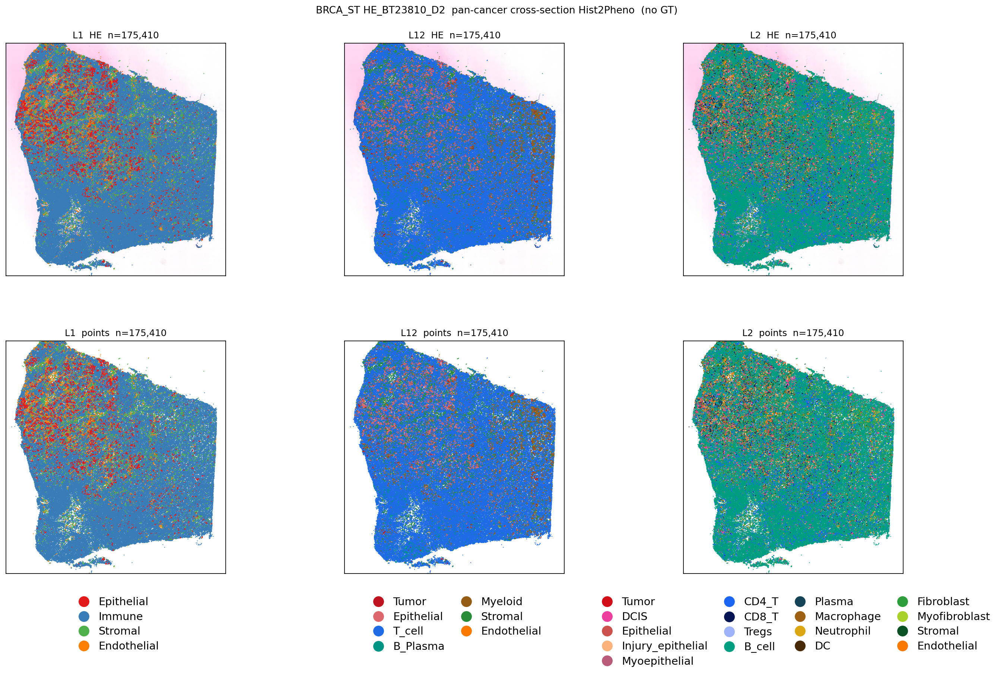

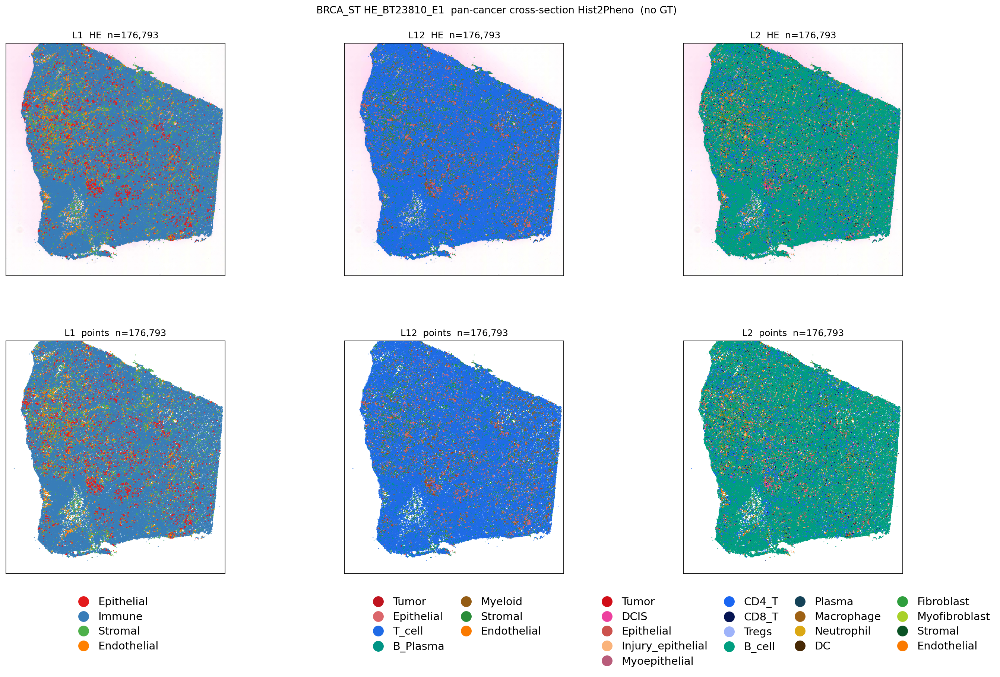

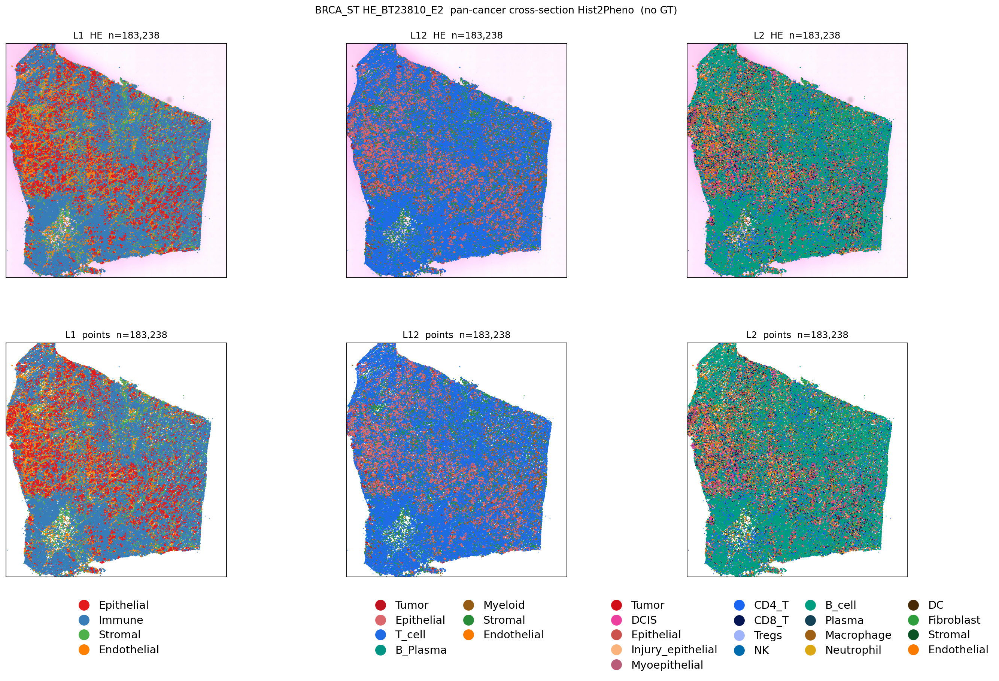

In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh predict"
    )

display(Markdown(f"## {PATIENT} — spatial labels"))
for fig in plot_spatial(
    group,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


## F — composition


===== F L1 =====


fraction                                 mean_conf  \
sample      HE_BT23810_D2 HE_BT23810_E1 HE_BT23810_E2 HE_BT23810_D2   
class                                                                 
Immune              0.804         0.841         0.666         0.661   
Epithelial          0.081         0.063         0.178         0.538   
Endothelial         0.049         0.039         0.104         0.400   
Stromal             0.066         0.057         0.053         0.428   

                                                    n                \
sample      HE_BT23810_E1 HE_BT23810_E2 HE_BT23810_D2 HE_BT23810_E1   
class                                                                 
Immune              0.656         0.625      141022.0      148650.0   
Epithelial          0.533         0.573       14181.0       11205.0   
Endothelial         0.397         0.411        8618.0        6873.0   
Stromal             0.413         0.426       11589.0       10065.0   

                           
sample      HE_BT23810_E2  
class                      
Immune           122036.0  
Epithelial        32546.0  
Endothelial       18978.0  
Stromal            9678.0


===== F L12 =====


fraction                                 mean_conf  \
sample      HE_BT23810_D2 HE_BT23810_E1 HE_BT23810_E2 HE_BT23810_D2   
class                                                                 
T_cell              0.797         0.833         0.717         0.493   
Epithelial          0.046         0.036         0.127         0.432   
Stromal             0.056         0.045         0.060         0.357   
Myeloid             0.056         0.034         0.051         0.351   
B_Plasma            0.036         0.046         0.026         0.458   
Tumor               0.008         0.005         0.014         0.446   
Endothelial         0.001         0.001         0.005         0.278   

                                                    n                \
sample      HE_BT23810_E1 HE_BT23810_E2 HE_BT23810_D2 HE_BT23810_E1   
class                                                                 
T_cell              0.490         0.470      139880.0      147284.0   
Epithelial          0.421         0.463        8072.0        6355.0   
Stromal             0.345         0.353        9774.0        7993.0   
Myeloid             0.333         0.329        9781.0        6065.0   
B_Plasma            0.444         0.443        6275.0        8119.0   
Tumor               0.425         0.457        1397.0         843.0   
Endothelial         0.277         0.280         231.0         134.0   

                           
sample      HE_BT23810_E2  
class                      
T_cell           131357.0  
Epithelial        23328.0  
Stromal           10931.0  
Myeloid            9322.0  
B_Plasma           4722.0  
Tumor              2585.0  
Endothelial         993.0


===== F L2 =====


fraction                                 mean_conf  \
sample            HE_BT23810_D2 HE_BT23810_E1 HE_BT23810_E2 HE_BT23810_D2   
class                                                                       
B_cell                    0.649         0.717         0.524         0.429   
CD4_T                     0.136         0.128         0.135         0.305   
Fibroblast                0.084         0.069         0.069         0.224   
CD8_T                     0.022         0.016         0.055         0.195   
Endothelial               0.020         0.013         0.050         0.192   
Epithelial                0.015         0.006         0.042         0.227   
Injury_epithelial         0.015         0.018         0.036         0.282   
DCIS                      0.021         0.014         0.035         0.357   
Myoepithelial             0.004         0.001         0.020         0.204   
Plasma                    0.014         0.010         0.015         0.245   
DC                        0.005         0.002         0.008         0.205   
Neutrophil                0.007         0.003         0.003         0.202   
Stromal                   0.004         0.001         0.004         0.255   
Tregs                     0.003         0.002         0.002         0.221   
Tumor                     0.001         0.000         0.001         0.219   
Macrophage                0.000         0.000         0.001         0.129   
NK                          NaN           NaN         0.000           NaN   
Myofibroblast             0.000         0.000           NaN         0.148   

                                                          n                \
sample            HE_BT23810_E1 HE_BT23810_E2 HE_BT23810_D2 HE_BT23810_E1   
class                                                                       
B_cell                    0.432         0.395      113881.0      126721.0   
CD4_T                     0.307         0.284       23769.0       22551.0   
Fibroblast                0.222         0.223       14700.0       12192.0   
CD8_T                     0.204         0.203        3919.0        2842.0   
Endothelial               0.193         0.195        3502.0        2302.0   
Epithelial                0.229         0.251        2631.0        1088.0   
Injury_epithelial         0.294         0.296        2711.0        3118.0   
DCIS                      0.353         0.387        3751.0        2511.0   
Myoepithelial             0.188         0.240         632.0         161.0   
Plasma                    0.247         0.242        2467.0        1807.0   
DC                        0.199         0.207         881.0         436.0   
Neutrophil                0.192         0.194        1214.0         487.0   
Stromal                   0.254         0.247         675.0         145.0   
Tregs                     0.214         0.189         519.0         336.0   
Tumor                     0.217         0.206         128.0          62.0   
Macrophage                0.124         0.148          28.0          32.0   
NK                          NaN         0.195           NaN           NaN   
Myofibroblast             0.142           NaN           2.0           2.0   

                                 
sample            HE_BT23810_E2  
class                            
B_cell                  95945.0  
CD4_T                   24700.0  
Fibroblast              12654.0  
CD8_T                   10136.0  
Endothelial              9195.0  
Epithelial               7709.0  
Injury_epithelial        6603.0  
DCIS                     6480.0  
Myoepithelial            3734.0  
Plasma                   2726.0  
DC                       1477.0  
Neutrophil                552.0  
Stromal                   788.0  
Tregs                     277.0  
Tumor                     142.0  
Macrophage                112.0  
NK                          8.0  
Myofibroblast               NaN

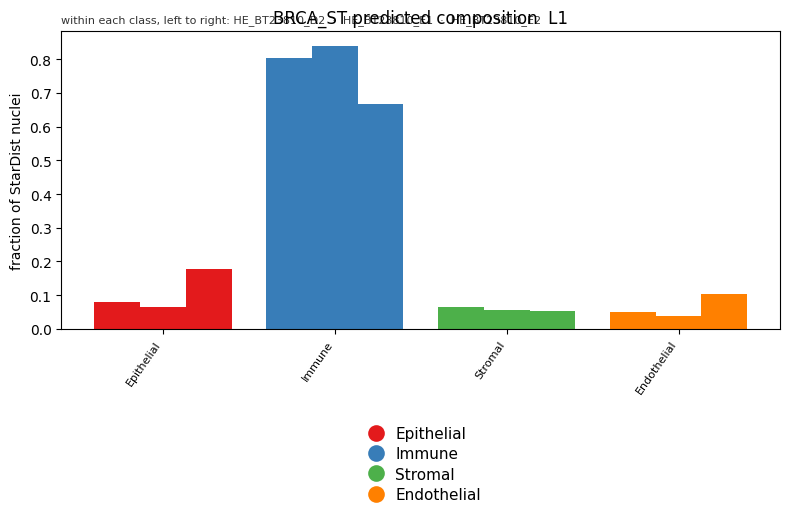

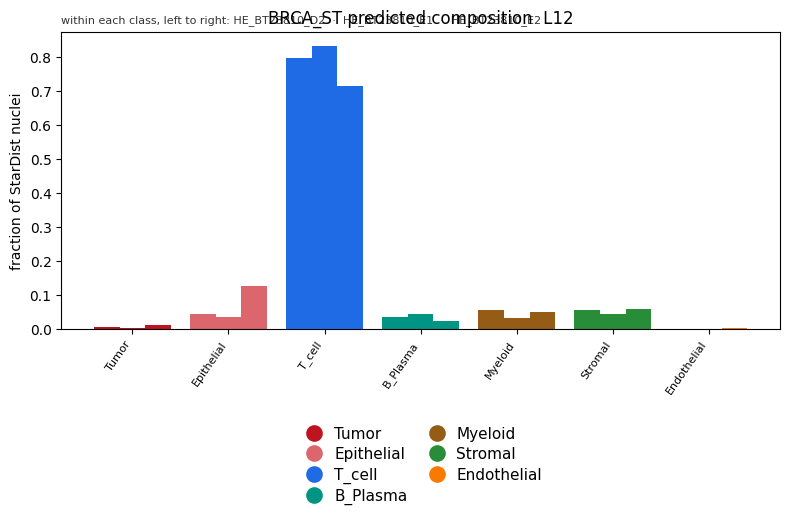

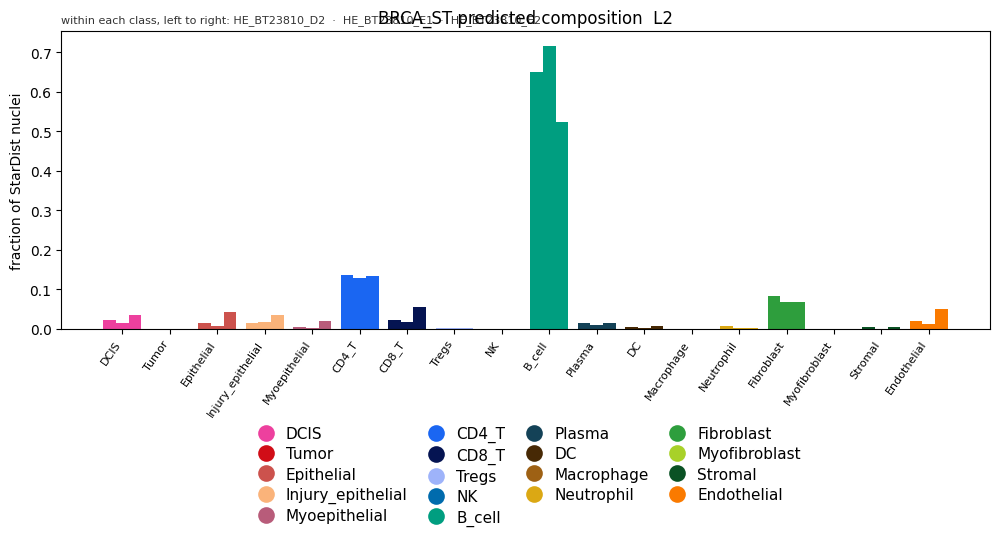

In [3]:
display(Markdown(f"## {PATIENT} — composition"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

for fig in plot_composition(group, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [4]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## F — TLS / SRI / TNI

[niche] cache HE_BT23810_D2_niche_indices.h5ad  n=175,410  µm/px=0.6876
  TLS hotspot: {'n_cells_total': 175410, 'n_candidate_cells': 8771, 'fraction_candidate': 0.050002850464625735, 'max_tls_spatial': 0.2387548485443927, 'mean_tls_spatial_candidate': 0.19371755252445433, 'centroid_x': 4977.773238738876, 'centroid_y': 6864.683643341499}
  mean TLS=0.629  TLS_spatial=0.153  SRI=25.140  TNI=38.455
[niche] cache HE_BT23810_E1_niche_indices.h5ad  n=176,793  µm/px=0.6892
  TLS hotspot: {'n_cells_total': 176793, 'n_candidate_cells': 8840, 'fraction_candidate': 0.05000197971639148, 'max_tls_spatial': 0.22764608657581395, 'mean_tls_spatial_candidate': 0.1892659812143155, 'centroid_x': 4801.4765440908495, 'centroid_y': 5070.545825805554}
  mean TLS=0.660  TLS_spatial=0.158  SRI=15.501  TNI=27.265
[niche] cache HE_BT23810_E2_niche_indices.h5ad  n=183,238  µm/px=0.6887
  TLS hotspot: {'n_cells_total': 183238, 'n_candidate_cells': 9162, 'fraction_candidate': 0.050000545738329384, 'max_tls_spatial

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,HE_BT23810_D2,175410,0.629,0.652,0.955,0.994,0.153,0.156,0.186,0.239,0.535,0.527,0.046,0.088,0.169,0.765
1,HE_BT23810_E1,176793,0.660,0.693,0.956,0.995,0.158,0.160,0.182,0.228,0.464,0.447,0.038,0.074,0.169,0.767
2,HE_BT23810_E2,183238,0.568,0.576,0.948,0.993,0.145,0.148,0.186,0.216,0.627,0.632,0.079,0.147,0.175,0.801


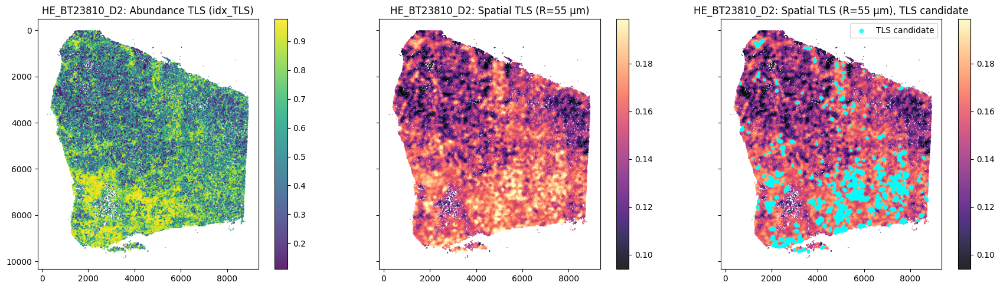

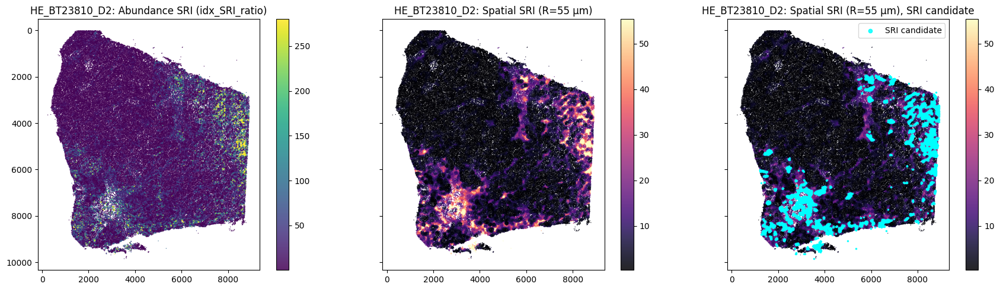

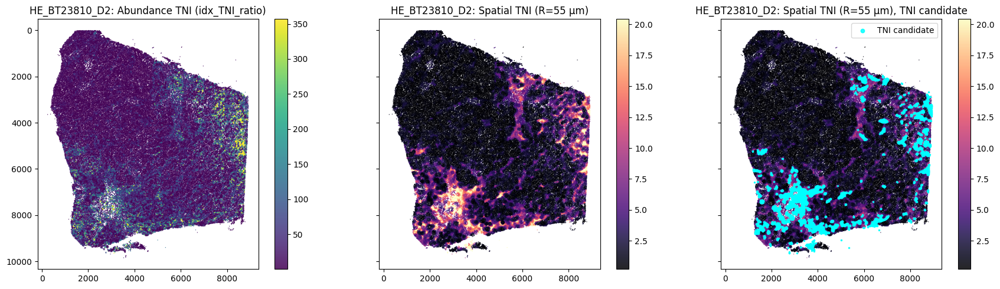

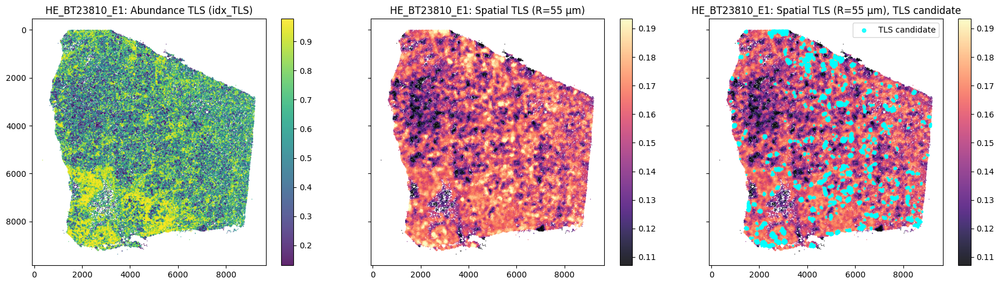

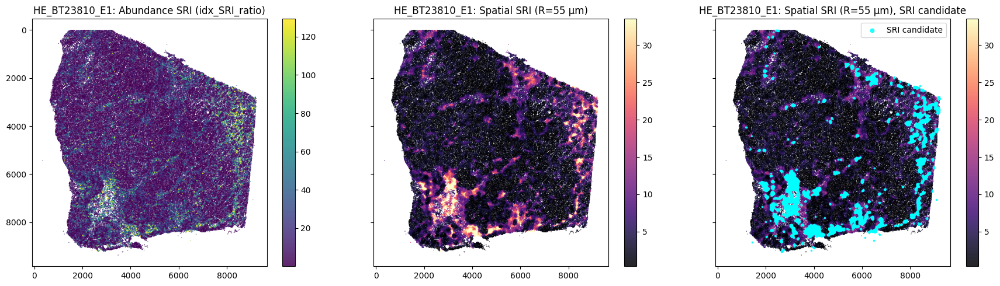

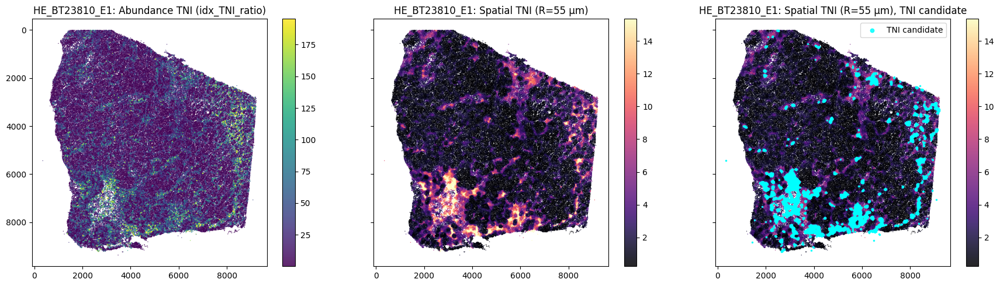

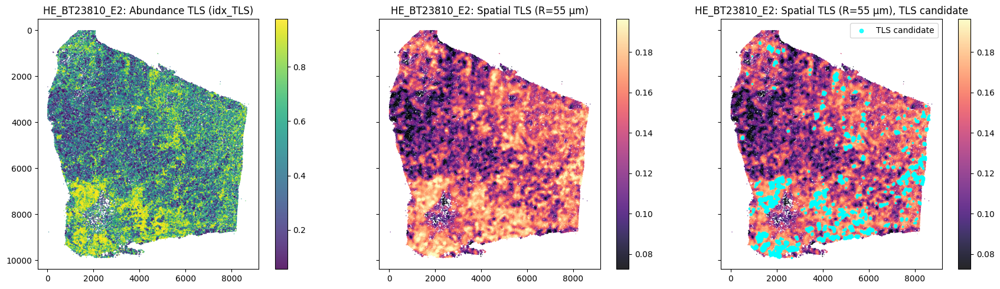

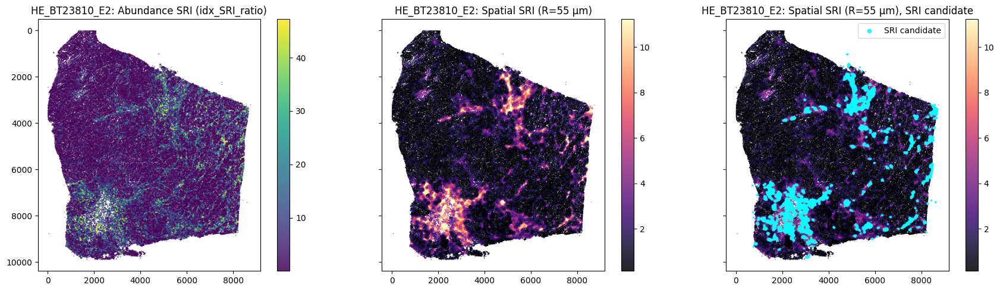

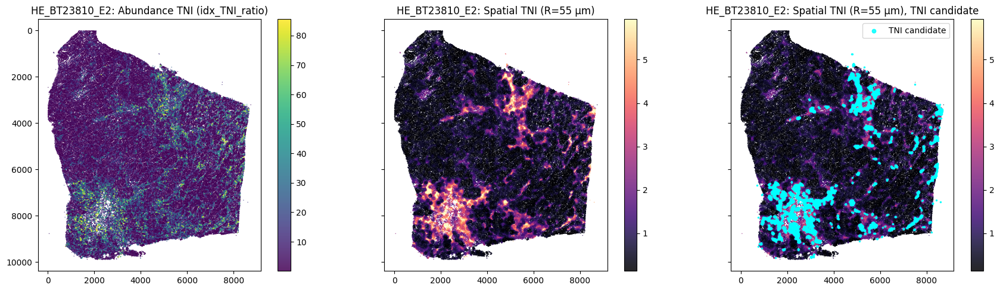

In [5]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
